In [51]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    mean_squared_error, mean_absolute_error, r2_score
)

import warnings
warnings.filterwarnings('ignore')

In [52]:
df = pd.read_csv('housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [53]:
print('Shape:', df.shape)
df.info()

Shape: (20640, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [54]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [55]:
df.duplicated().sum()

np.int64(0)

In [56]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

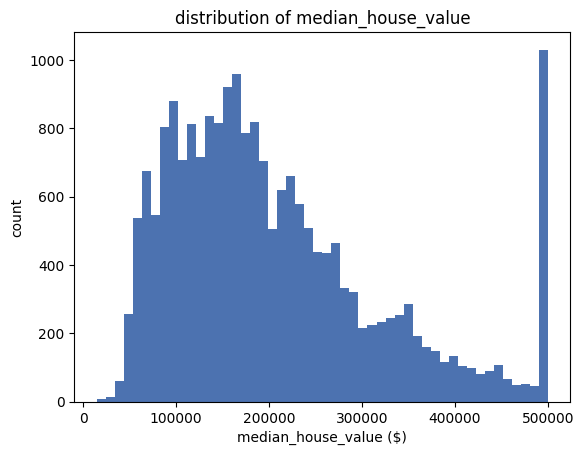

In [57]:
plt.Figure(figsize=(8,4))
plt.hist(df['median_house_value'], bins= 50, color='#4c72b0')
plt.title('distribution of median_house_value')
plt.xlabel('median_house_value ($)')
plt.ylabel('count')
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

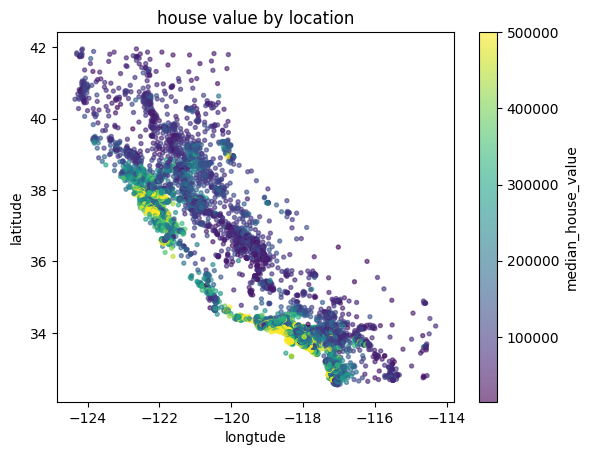

In [58]:
plt.Figure(figsize=(8,6))
sc = plt.scatter(df['longitude'], df['latitude'], c = df['median_house_value'], cmap='viridis', s = 8, alpha=0.6)
plt.colorbar(sc, label='median_house_value')
plt.xlabel('longtude')
plt.ylabel('latitude')
plt.title('house value by location')
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

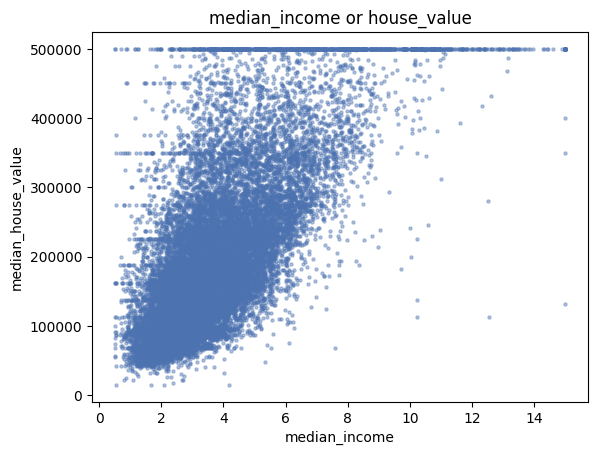

In [59]:
plt.Figure(figsize=(8,4))
plt.scatter(df['median_income'], df['median_house_value'],s=5,alpha=0.4, color='#4c72b0')
plt.xlabel('median_income')
plt.ylabel('median_house_value')
plt.title('median_income or house_value')
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

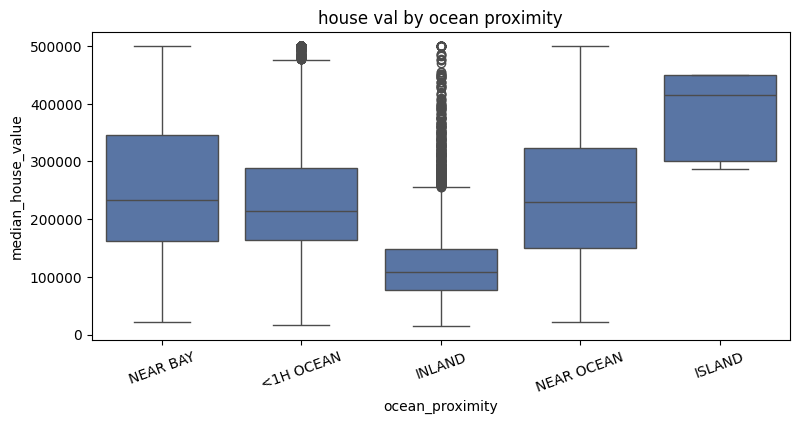

In [60]:
plt.figure(figsize=(9,4))
sns.boxplot(data=df, x='ocean_proximity', y='median_house_value', color='#4c72b0')
plt.title('house val by ocean proximity')
plt.xticks(rotation=20)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

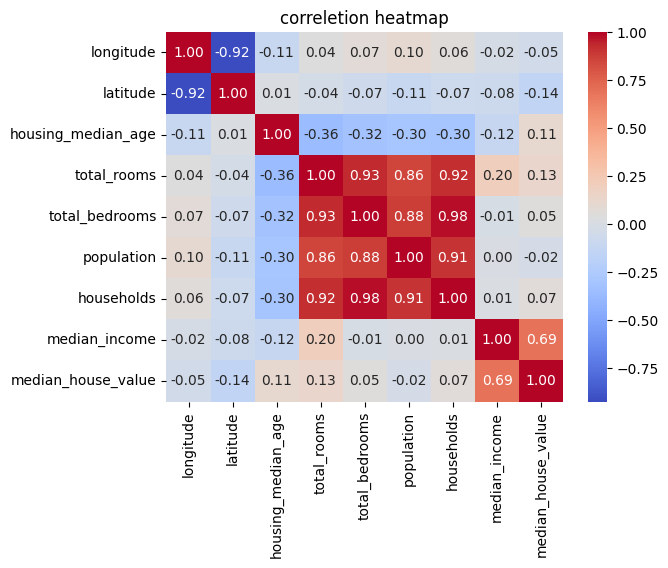

In [61]:
plt.Figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only = True),annot=True, fmt='.2f', cmap='coolwarm')
plt.title('correletion heatmap')
plt.show

In [62]:
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())
df.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [63]:
cols = ['housing_median_age','total_rooms', 'total_bedrooms', 'population', 'households', 'median_income','']

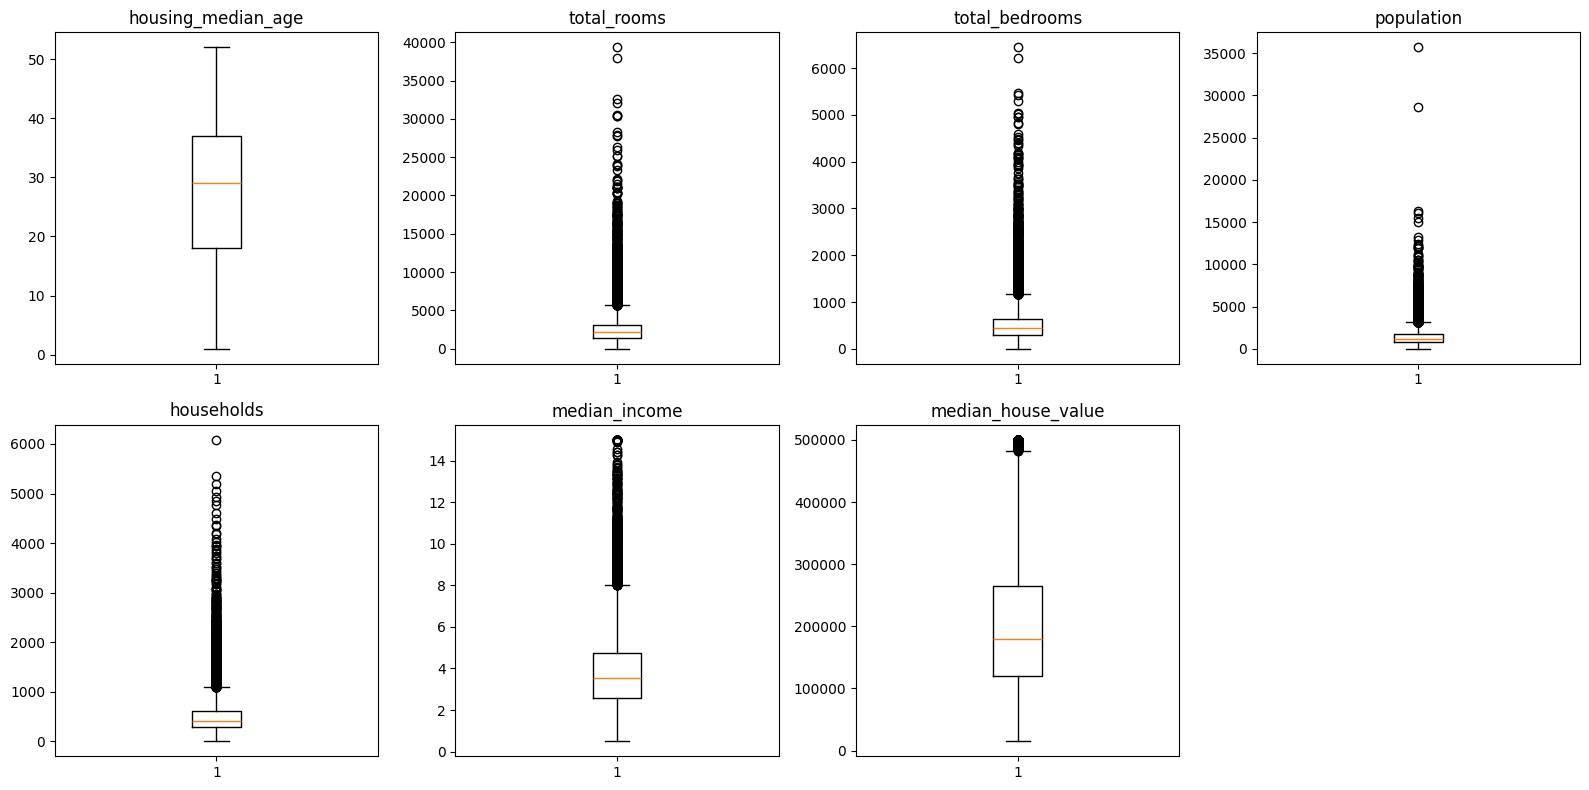

In [64]:
cols = ['housing_median_age', 'total_rooms', 'total_bedrooms',
        'population', 'households', 'median_income', 'median_house_value']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), cols):
    ax.boxplot(df[col].dropna())
    ax.set_title(col)
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

In [65]:
df['rooms_per_household']      = df['total_rooms'] / df['households']
df['bedrooms_per_room']        = df['total_bedrooms'] / df['total_rooms']
df['population_per_household'] = df['population'] / df['households']

In [66]:
df['ocean_proximity'] = df['ocean_proximity'].astype(str)

cat_cols = ['ocean_proximity']
num_cols = ['longitude', 'latitude', 'housing_median_age',
            'total_rooms', 'total_bedrooms', 'population', 'households',
            'median_income', 'rooms_per_household', 'bedrooms_per_room',
            'population_per_household']

X = pd.get_dummies(df[cat_cols + num_cols], columns=cat_cols,
                   drop_first=True, dtype=int)
y = df['median_house_value']

print('Shape:', X.shape)
X.head()

Shape: (20640, 15)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,bedrooms_per_room,population_per_household,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,6.984127,0.146591,2.555556,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,6.238137,0.155797,2.109842,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,8.288136,0.129516,2.802260,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,5.817352,0.184458,2.547945,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,6.281853,0.172096,2.181467,0,0,1,0


In [67]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('X_train:', X_train.shape)
print('X_test :', X_test.shape)

X_train: (16512, 15)
X_test : (4128, 15)


In [68]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [69]:
models = {
    'Linear Regression':  LinearRegression(),
    'Ridge (alpha=1.0)':  Ridge(alpha=1.0),
    'Lasso (alpha=1.0)':  Lasso(alpha=1.0, max_iter=10000),
}

results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    results[name] = {
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'MAE' : mean_absolute_error(y_test, pred),
        'R2'  : r2_score(y_test, pred),
    }

results_df = pd.DataFrame(results).T
results_df

,RMSE,MAE,R2
Linear Regression,72668.538379,50888.660016,0.597018
Ridge (alpha=1.0),72666.348221,50888.319653,0.597042
Lasso (alpha=1.0),72667.021851,50888.053644,0.597035


In [70]:
lr = LinearRegression()
cv_r2   = cross_val_score(lr, X_train_scaled, y_train, cv=5, scoring='r2')
cv_rmse = -cross_val_score(lr, X_train_scaled, y_train, cv=5,
                           scoring='neg_root_mean_squared_error')

print('CV R2  :', np.round(cv_r2, 4), '| mean =', round(cv_r2.mean(), 4))
print('CV RMSE:', np.round(cv_rmse, 0), '| mean =', round(cv_rmse.mean(), 0))

CV R2  : [0.6618 0.6583 0.6673 0.6574 0.6325] | mean = 0.6555
CV RMSE: [68044. 66595. 66935. 66857. 70813.] | mean = 67849.0


In [71]:
lr.fit(X_train_scaled, y_train)
coefs = pd.Series(lr.coef_, index=X.columns).sort_values(key=abs, ascending=False)
coefs

median_income                 78904.439397
latitude                     -56638.231159
longitude                    -56276.058852
population                   -46320.285471
households                    40233.724848
bedrooms_per_room             16809.104551
ocean_proximity_INLAND       -16257.039232
housing_median_age            14122.304752
rooms_per_household            7699.448488
total_rooms                    5881.104980
total_bedrooms                 5307.662997
ocean_proximity_ISLAND         2034.426108
ocean_proximity_NEAR BAY      -1718.333533
ocean_proximity_NEAR OCEAN      996.583711
population_per_household        750.367943
dtype: float64

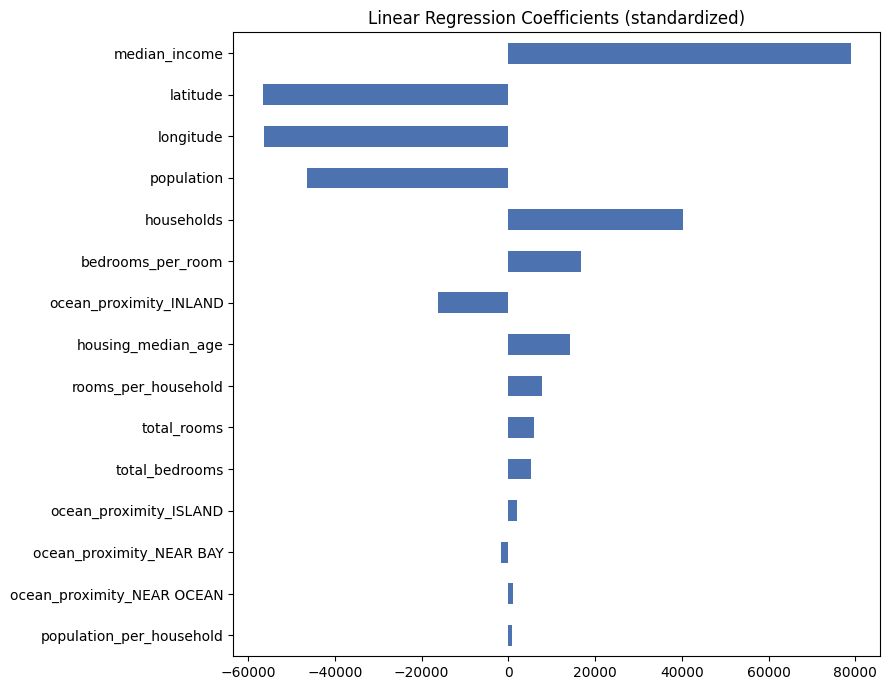

In [72]:
plt.figure(figsize=(9, 7))
coefs.plot(kind='barh', color='#4c72b0')
plt.title('Linear Regression Coefficients (standardized)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [73]:
best_name  = min(results, key=lambda k: results[k]['RMSE'])
best_model = models[best_name]
y_pred     = best_model.predict(X_test_scaled)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae  = mean_absolute_error(y_test, y_pred)
r2   = r2_score(y_test, y_pred)

print('Best model :', best_name)
print(f'RMSE       : ${rmse:,.0f}')
print(f'MAE        : ${mae:,.0f}')
print(f'R2         : {r2:.4f}')

Best model : Ridge (alpha=1.0)
RMSE       : $72,666
MAE        : $50,888
R2         : 0.5970


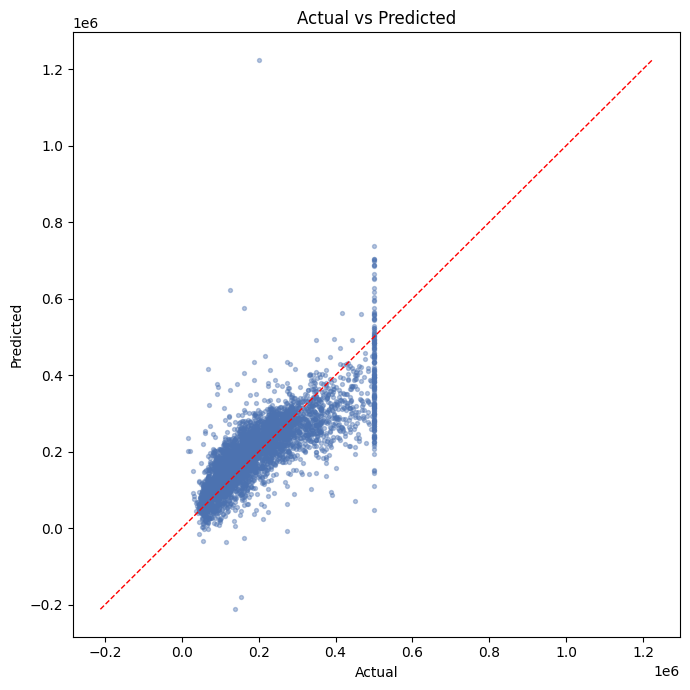

In [74]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, s=8, alpha=0.4, color='#4c72b0')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', linewidth=1)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted')
plt.tight_layout()
plt.show()

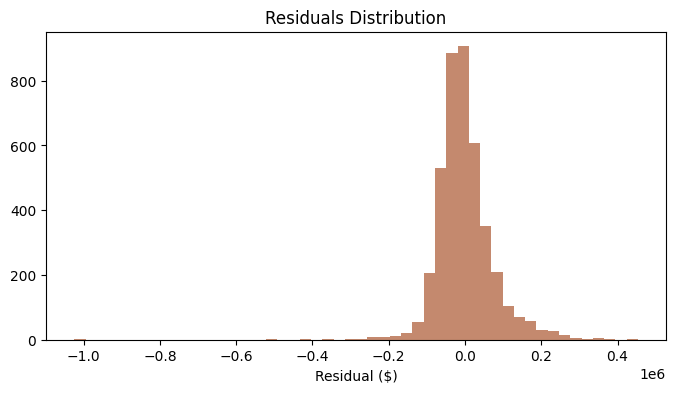

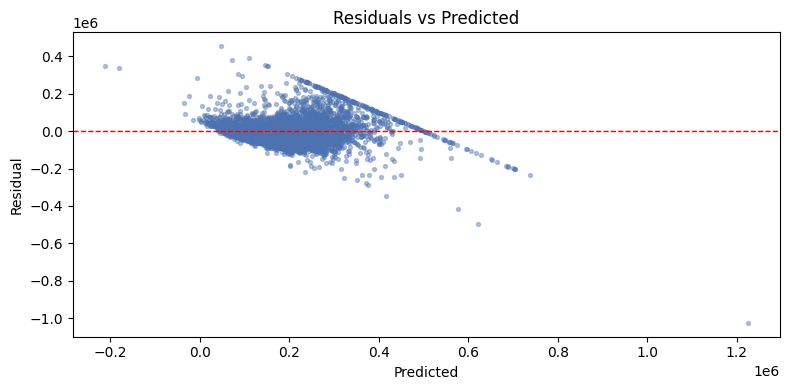

In [75]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 4))
plt.hist(residuals, bins=50, color='#c4896e')
plt.title('Residuals Distribution')
plt.xlabel('Residual ($)')
plt.show()

plt.figure(figsize=(8, 4))
plt.scatter(y_pred, residuals, s=8, alpha=0.4, color='#4c72b0')
plt.axhline(0, color='r', linestyle='--', linewidth=1)
plt.xlabel('Predicted')
plt.ylabel('Residual')
plt.title('Residuals vs Predicted')
plt.tight_layout()
plt.show()